# Analyse des 16 configurations SloshingPINN

Ce notebook analyse les 16 modèles generes par `script/benchmark_combinations.py`.
Nous etudions la convergence par modele, la convergence globale, les residus,
et l'impact de chaque feature (Fourier, adaptive sampling, segmentation temporelle,
et pondulation adaptative).

*Sources de donnees :* `reports/summary.json`, `reports/model_table.json`,
les historiques dans `models/*/history.json`, les erreurs dans `reports/errors_*.npz`,
et les fichiers adaptatifs selon les flags actives.


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import json
import matplotlib
import matplotlib.pyplot as plt

import torch
from config import Config
from model import SloshingPINN
from visualization import plot_history, plot_histories, plot_residuals, load_model

# Chemins des resultats
REPORTS = ROOT / "reports"
MODELS = ROOT / "models"

# Chargement du recapitulatif et du tableau de models
with open(REPORTS / "summary.json", "r", encoding="utf-8") as f:
    summary = json.load(f)

with open(REPORTS / "model_table.json", "r", encoding="utf-8") as f:
    model_table = json.load(f)

df_summary = pd.DataFrame(summary)
df_table = pd.DataFrame(model_table)

print("Modèles :", df_table["model_name"].tolist())
print("\nRésumé RMSE moyen :")
print(df_summary[['model_name', 'mean_rmse_u', 'mean_rmse_v', 'mean_rmse_p', 'mean_rmse_alpha', 'train_time_s']].to_string(index=False))


Modèles : ['model_ff0_as0_ts0_alw0', 'model_ff0_as0_ts0_alw1', 'model_ff0_as0_ts1_alw0', 'model_ff0_as0_ts1_alw1', 'model_ff0_as1_ts0_alw0', 'model_ff0_as1_ts0_alw1', 'model_ff0_as1_ts1_alw0', 'model_ff0_as1_ts1_alw1', 'model_ff1_as0_ts0_alw0', 'model_ff1_as0_ts0_alw1', 'model_ff1_as0_ts1_alw0', 'model_ff1_as0_ts1_alw1', 'model_ff1_as1_ts0_alw0', 'model_ff1_as1_ts0_alw1', 'model_ff1_as1_ts1_alw0', 'model_ff1_as1_ts1_alw1']

Résumé RMSE moyen :
            model_name  mean_rmse_u  mean_rmse_v  mean_rmse_p  mean_rmse_alpha  train_time_s
model_ff0_as0_ts0_alw0     0.770198     0.187634  4287.142996         0.486755     55.765126
model_ff0_as0_ts0_alw1     0.770299     0.190361  4331.503428         0.486144     84.644174
model_ff0_as0_ts1_alw0     0.768456     0.191136  4191.402628         0.492456     51.651918
model_ff0_as0_ts1_alw1     0.769949     0.193427  4170.121024         0.492477     74.547491
model_ff0_as1_ts0_alw0     0.768281     0.187566  3954.932713         0.482396     56.2

## 1. Convergence par modèle (16 figures)

Pour chaque modèle, nous affichons l'historique de toutes les pertes entraînement
(continuity, vof, momentum_x, momentum_y, initial_u, initial_v, initial_alpha,
wall_u, wall_v, pressure_gauge) via `plot_history`.


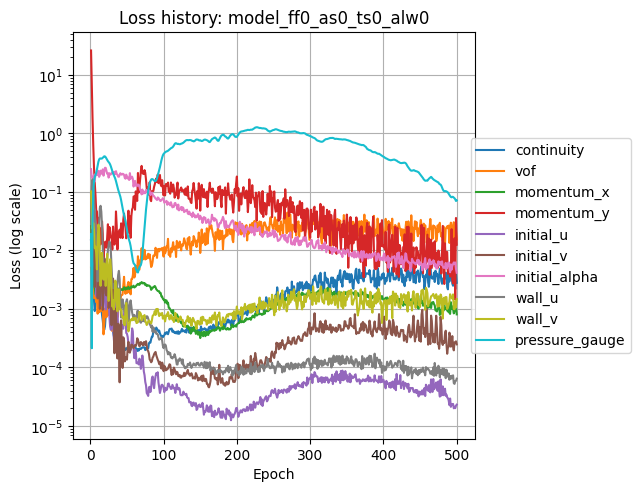

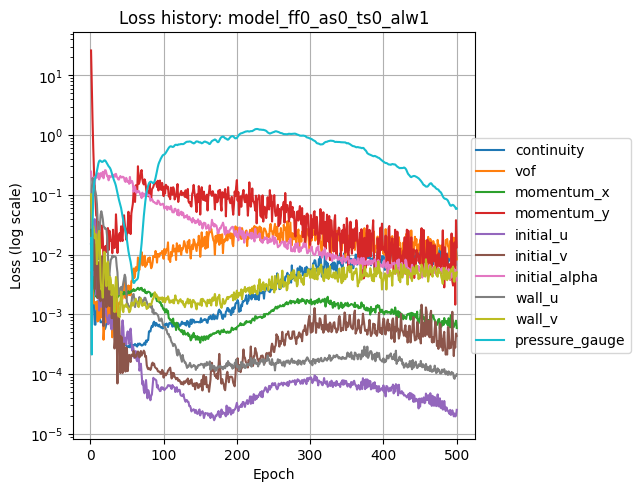

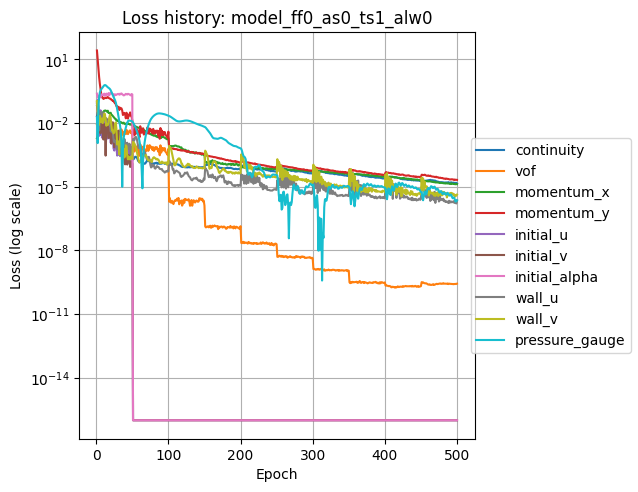

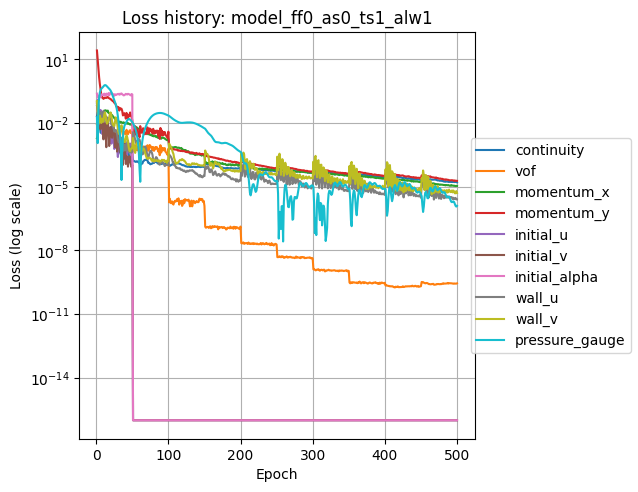

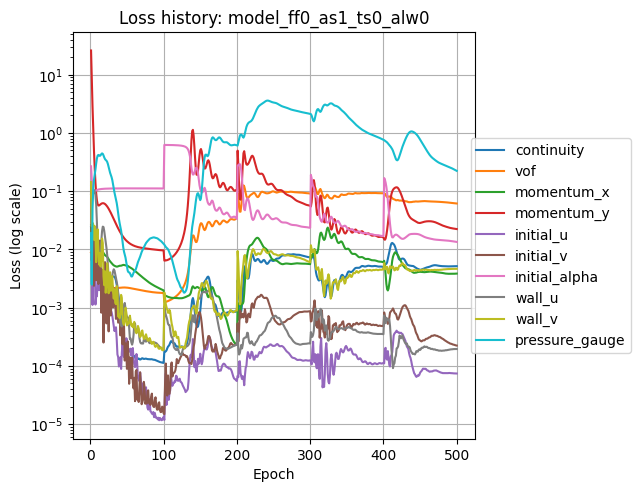

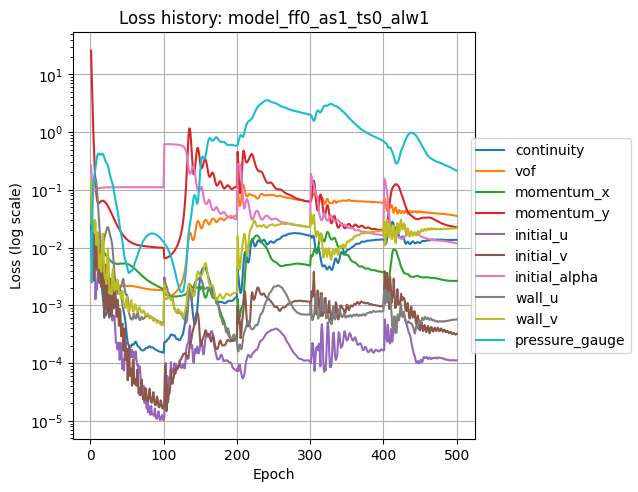

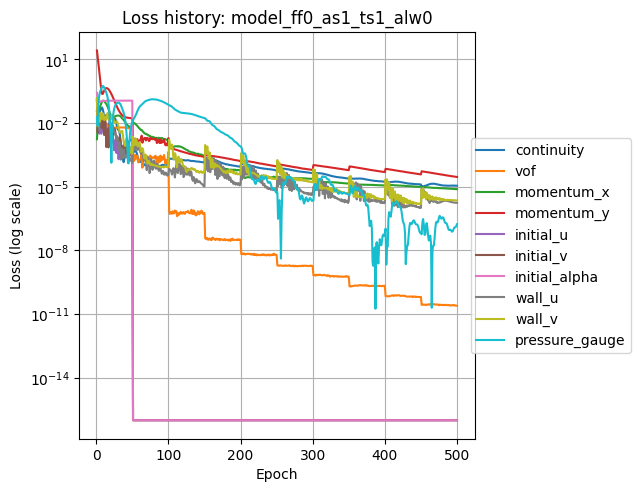

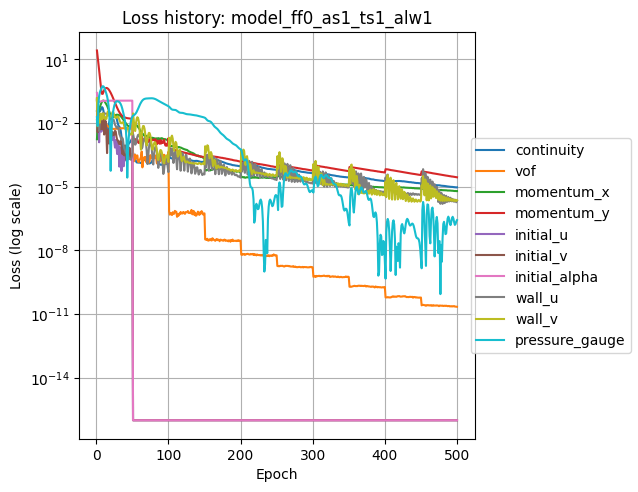

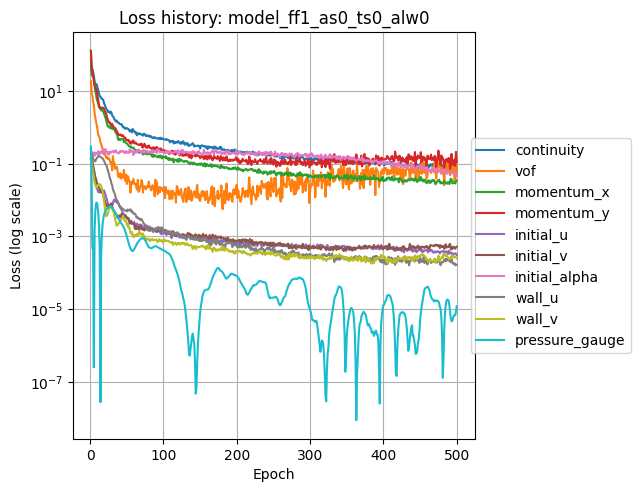

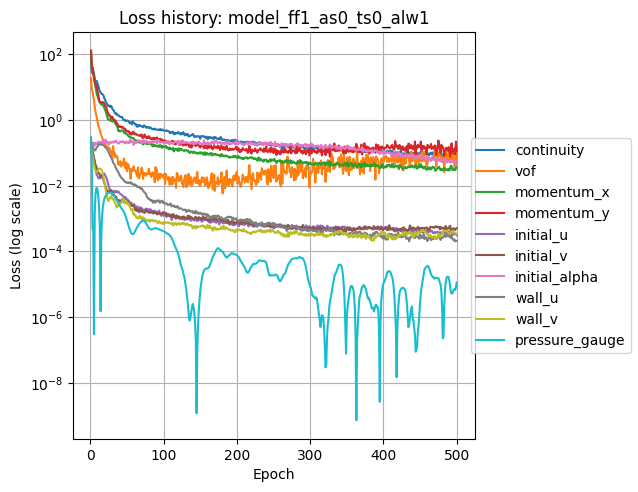

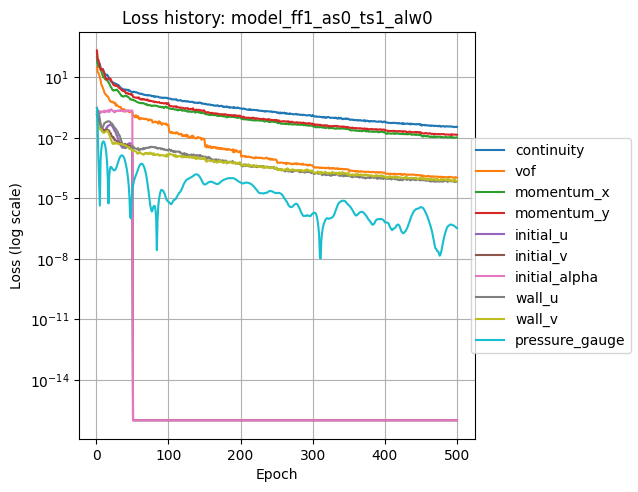

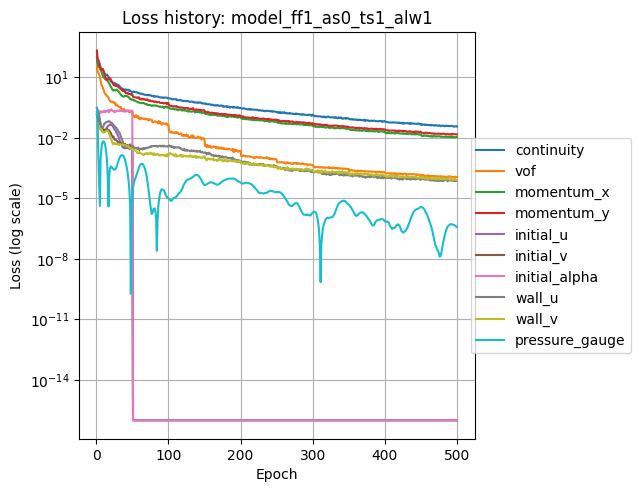

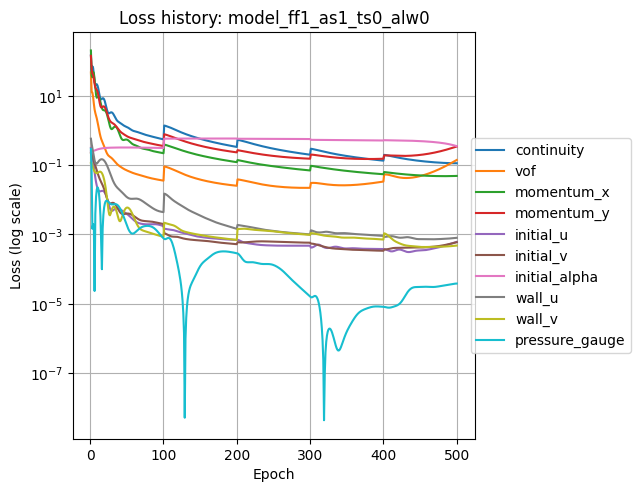

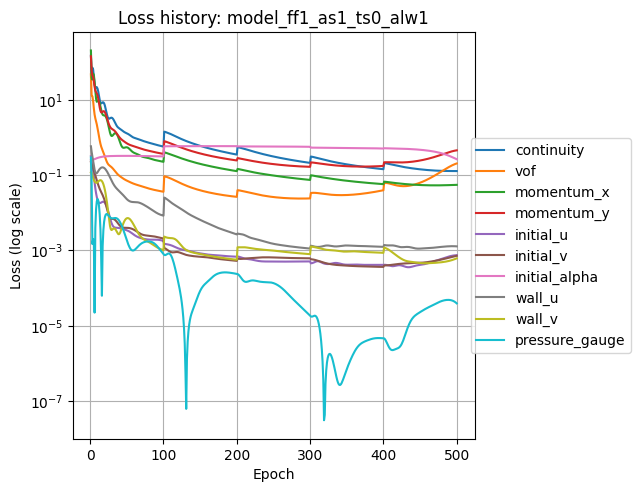

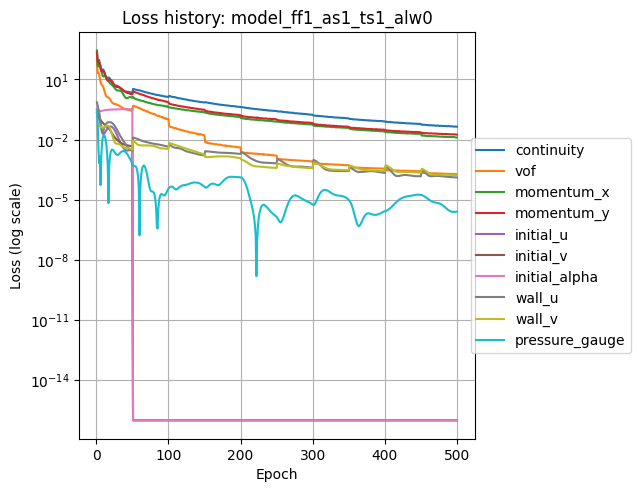

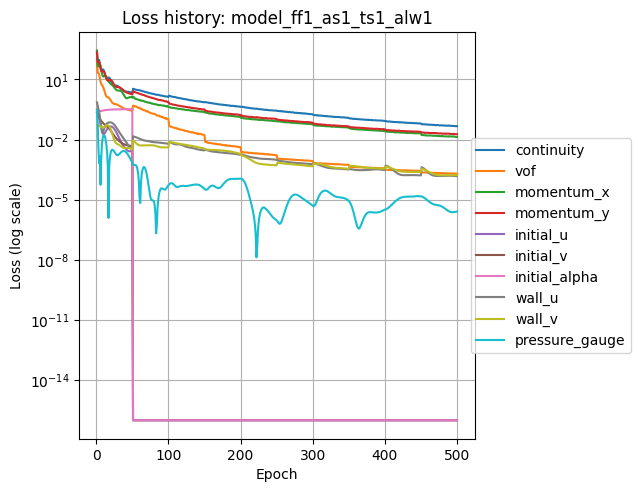

In [2]:
loss_names = [
    "continuity", "vof", "momentum_x", "momentum_y",
    "initial_u", "initial_v", "initial_alpha",
    "wall_u", "wall_v", "pressure_gauge"
]

for model_name in df_table["model_name"]:
    hist_path = MODELS / model_name / "history.json"
    if hist_path.is_file():
        fig, ax = plot_history(path=str(hist_path), loss_names=loss_names, 
                               title=f"Loss history: {model_name}",
                               use_same_figure=True, legend=True)
        plt.savefig(ROOT / "reports" / "figures" / f"convergence_{model_name}.png", dpi=150, bbox_inches="tight")
    else:
        print(f"Avertissement: {hist_path} introuvable")
plt.show()

## 2. Convergence globale de tous les modèles

Comparaison de la perte `total` sur une même figure pour les 16 modèles.


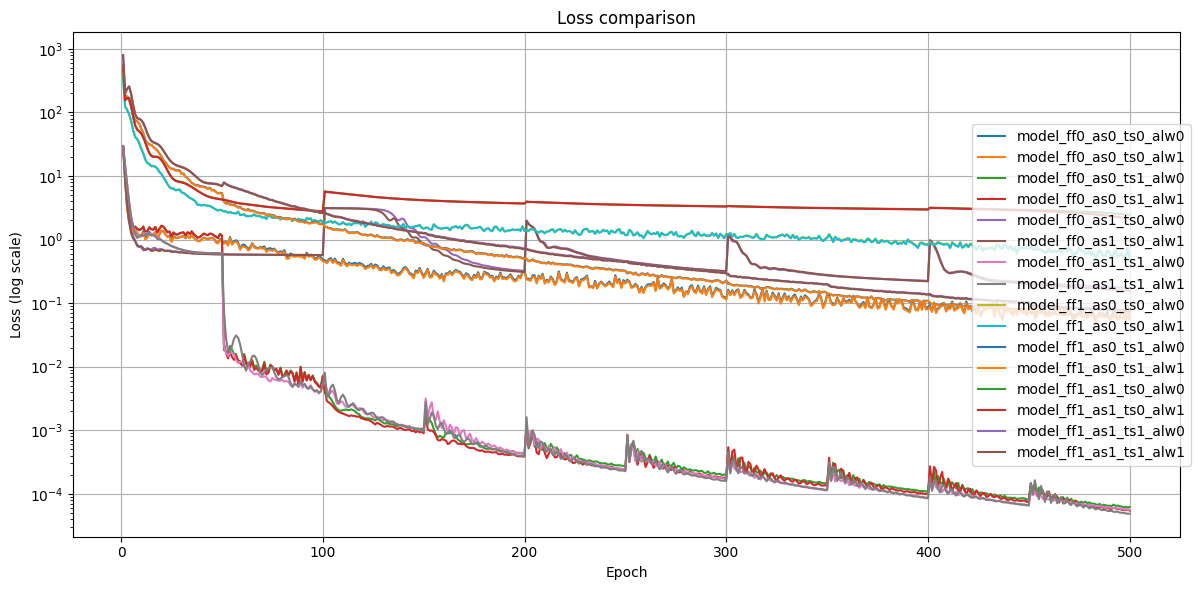

In [3]:
paths = []
names = []
for model_name in df_table["model_name"]:
    hist_path = MODELS / model_name / "history.json"
    if hist_path.is_file():
        paths.append(str(hist_path))
        names.append(model_name)

fig, ax = plot_histories(paths=paths, names=names)
plt.savefig(ROOT / "reports" / "figures" / "convergence_global.png", dpi=150, bbox_inches="tight")
# plt.close(fig)
plt.show()



## 3. Cartes des résidus

Nous chargeons un modèle représentatif (baseline `model_ff0_as0_ts0_alw0`
et le meilleur selon RMSE α) et générons des cartes de résidus via `plot_residuals`.


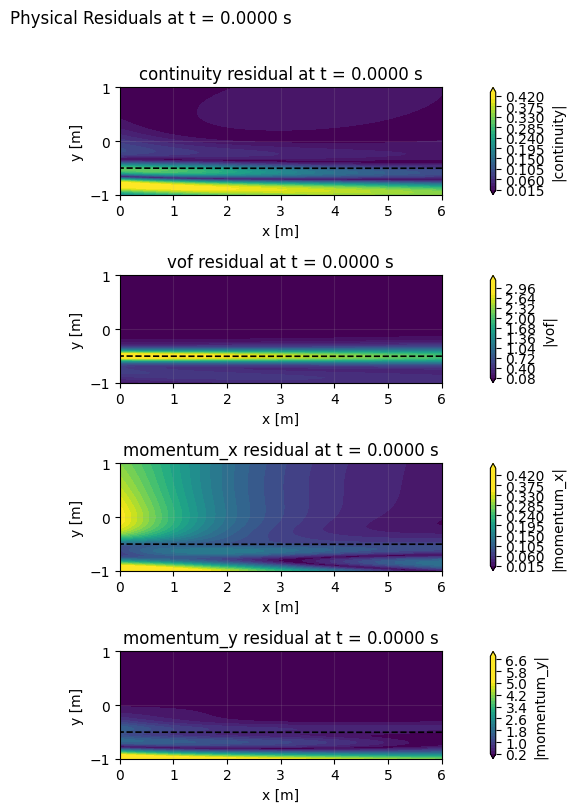

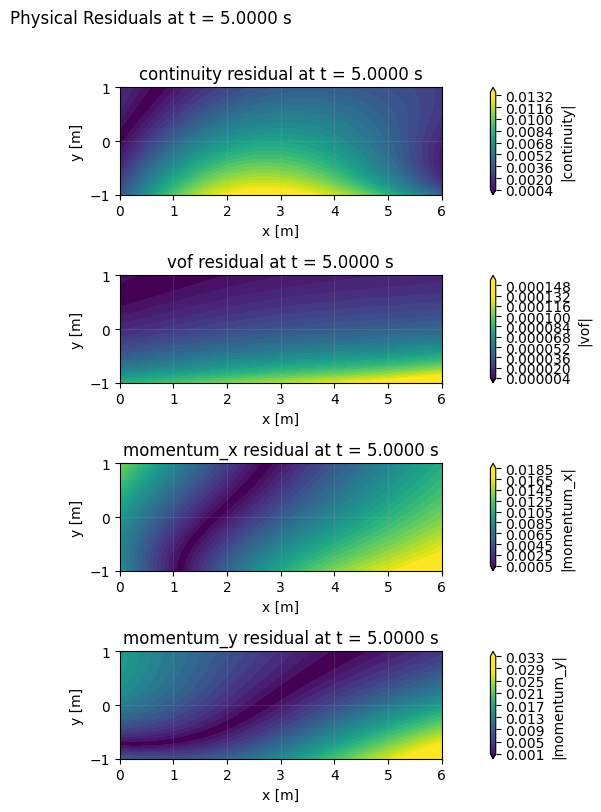

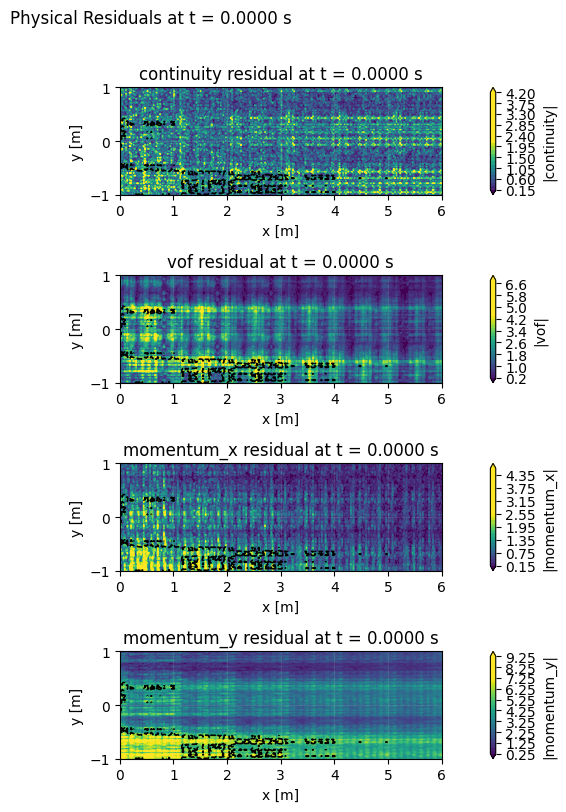

Meilleur RMSE alpha: model_ff1_as1_ts0_alw1 (RMSE α = 0.4807)


In [4]:
# Modèle baseline
baseline_name = "model_ff0_as0_ts0_alw0"
cfg = Config.load_json(str(MODELS / baseline_name / "config.json"))
model = load_model(str(MODELS / baseline_name / "checkpoint_final.pt"), config=cfg)

# Tracer les résidus à t=0.0 et t=5.0
for t in [0.0, 5.0]:
    fig = plot_residuals(model, t=t, fields=("continuity", "vof", "momentum_x", "momentum_y"),
                         overlay_vof=True, figsize=(10, 8))
    plt.savefig(ROOT / "reports" / "figures" / f"residus_{baseline_name}_t{t}.png", dpi=150, bbox_inches="tight")
    # plt.close(fig)

# Modèle avec meilleur RMSE alpha
best_alpha_name = df_summary.loc[df_summary['mean_rmse_alpha'].idxmin(), 'model_name']
cfg2 = Config.load_json(str(MODELS / best_alpha_name / "config.json"))
model2 = load_model(str(MODELS / best_alpha_name / "checkpoint_final.pt"), config=cfg2)
fig = plot_residuals(model2, t=0.0, fields=("continuity", "vof", "momentum_x", "momentum_y"),
                     overlay_vof=True, figsize=(10, 8))
plt.savefig(ROOT / "reports" / "figures" / f"residus_{best_alpha_name}_bestalpha.png", dpi=150, bbox_inches="tight")
# plt.close(fig)
plt.show()
print(f"Meilleur RMSE alpha: {best_alpha_name} (RMSE α = {df_summary.loc[df_summary['mean_rmse_alpha'].idxmin(), 'mean_rmse_alpha']:.4f})")


## 4. Analyse par feature activée

### 4.1 Features Fourier

Comparaison des modèles avec `use_fourier_features=True` vs `False` (mêmes autres flags).
Nous observons l'impact sur la convergence et les hautes fréquences spatiales.


In [5]:
# Regrouper les modèles par combinaison des 3 autres flags (sans Fourier)
ff_true = df_summary[df_summary['use_fourier_features'] == True]
ff_false = df_summary[df_summary['use_fourier_features'] == False]

print("Modèles avec Fourier features :")
print(ff_true[['model_name', 'mean_rmse_u', 'mean_rmse_v', 'mean_rmse_p', 'mean_rmse_alpha', 'train_time_s']].to_string(index=False))
print()
print("Modèles sans Fourier features :")
print(ff_false[['model_name', 'mean_rmse_u', 'mean_rmse_v', 'mean_rmse_p', 'mean_rmse_alpha', 'train_time_s']].to_string(index=False))


Modèles avec Fourier features :
            model_name  mean_rmse_u  mean_rmse_v  mean_rmse_p  mean_rmse_alpha  train_time_s
model_ff1_as0_ts0_alw0     0.769767     0.186901  4194.495938         0.488200     91.720059
model_ff1_as0_ts0_alw1     0.769574     0.186951  4193.759604         0.488113    130.347352
model_ff1_as0_ts1_alw0     0.768553     0.187687  4259.862058         0.489978     84.317982
model_ff1_as0_ts1_alw1     0.768584     0.187737  4259.864358         0.489906    116.996092
model_ff1_as1_ts0_alw0     0.769508     0.187191  4208.068661         0.481016     77.446821
model_ff1_as1_ts0_alw1     0.769796     0.187009  4197.041515         0.480712    115.417472
model_ff1_as1_ts1_alw0     0.767942     0.188368  4247.289422         0.489762     77.499402
model_ff1_as1_ts1_alw1     0.767851     0.188592  4246.721381         0.489672    117.352027

Modèles sans Fourier features :
            model_name  mean_rmse_u  mean_rmse_v  mean_rmse_p  mean_rmse_alpha  train_time_s
model

### 4.2 Adaptive sampling

Pour les modèles avec `use_adaptive_sampling=True`, nous analysons
l'historique des points collocation sélectionnés via `adaptive_history.npz`.


In [7]:
# Analyse de adaptive_history pour les modèles avec adaptive_sampling=True
as_models = df_table[df_table['use_adaptive_sampling'] == True]['model_name'].tolist()
print(f"Modèles avec adaptive sampling: {as_models}")

for model_name in as_models:
    adv_path = MODELS / model_name / "adaptive_history.npz"
    if adv_path.is_file():
        d = np.load(str(adv_path), allow_pickle=True)
        print(f"\n{model_name} :")
        print(f"  epochs: {d['epochs'].shape[0]}")
        print(f"  windows: {d['windows'].shape[0]}")
        print(f"  t_left range: [{float(d['t_left'].min()):.2f}, {float(d['t_left'].max()):.2f}]")
        print(f"  t_right range: [{float(d['t_right'].min()):.2f}, {float(d['t_right'].max()):.2f}]")
        # Tracer l'évolution du nombre de points par époque
        fig, ax = plt.subplots(figsize=(8, 4))
        ax.semilogy(d['epochs'], np.ones_like(d['epochs'])*100, 'o', alpha=0.6)
        ax.set_xlabel('Époque')
        ax.set_ylabel('Nombre de points (fixe pour affichage)')
        ax.set_title(f"Adaptive sampling: {model_name}")
        plt.savefig(ROOT / "reports" / "figures" / f"adaptive_{model_name}.png", dpi=150, bbox_inches="tight")
        plt.close(fig)
    else:
        print(f"Aucun adaptive_history.npz pour {model_name}")


Modèles avec adaptive sampling: ['model_ff0_as1_ts0_alw0', 'model_ff0_as1_ts0_alw1', 'model_ff0_as1_ts1_alw0', 'model_ff0_as1_ts1_alw1', 'model_ff1_as1_ts0_alw0', 'model_ff1_as1_ts0_alw1', 'model_ff1_as1_ts1_alw0', 'model_ff1_as1_ts1_alw1']

model_ff0_as1_ts0_alw0 :
  epochs: 5
  windows: 5
  t_left range: [0.00, 0.00]
  t_right range: [10.00, 10.00]

model_ff0_as1_ts0_alw1 :
  epochs: 5
  windows: 5
  t_left range: [0.00, 0.00]
  t_right range: [10.00, 10.00]

model_ff0_as1_ts1_alw0 :
  epochs: 10
  windows: 10
  t_left range: [0.00, 9.00]
  t_right range: [1.00, 10.00]

model_ff0_as1_ts1_alw1 :
  epochs: 10
  windows: 10
  t_left range: [0.00, 9.00]
  t_right range: [1.00, 10.00]

model_ff1_as1_ts0_alw0 :
  epochs: 5
  windows: 5
  t_left range: [0.00, 0.00]
  t_right range: [10.00, 10.00]

model_ff1_as1_ts0_alw1 :
  epochs: 5
  windows: 5
  t_left range: [0.00, 0.00]
  t_right range: [10.00, 10.00]

model_ff1_as1_ts1_alw0 :
  epochs: 10
  windows: 10
  t_left range: [0.00, 9.00]
  t

### 4.3 Segmentation temporelle

Pour les modèles avec `use_temporal_segmentation=True`, nous analysons
la structure des fenêtres temporelles et la convergence par segment.


In [8]:
# Analyse de la segmentation temporelle
ts_models = df_table[df_table['use_temporal_segmentation'] == True]['model_name'].tolist()
print(f"Modèles avec temporal segmentation: {ts_models}")

for model_name in ts_models:
    hist_path = MODELS / model_name / "history.json"
    if hist_path.is_file():
        d = json.load(open(str(hist_path)))
        windows = set(row.get('window', 0) for row in d)
        t_left_vals = [row.get('t_left', 0) for row in d]
        t_right_vals = [row.get('t_right', 0) for row in d]
        print(f"\n{model_name} :")
        print(f"  Fenêtres: {sorted(windows)}")
        print(f"  t_left range: [{min(t_left_vals):.2f}, {max(t_left_vals):.2f}]")
        print(f"  t_right range: [{min(t_right_vals):.2f}, {max(t_right_vals):.2f}]")
        # Compter les epochs par fenêtre
        from collections import Counter
        wc = Counter(row.get('window', 0) for row in d)
        print(f"  Épochs par fenêtre: {dict(sorted(wc.items))}")
    else:
        print(f"Aucun history.json pour {model_name}")


Modèles avec temporal segmentation: ['model_ff0_as0_ts1_alw0', 'model_ff0_as0_ts1_alw1', 'model_ff0_as1_ts1_alw0', 'model_ff0_as1_ts1_alw1', 'model_ff1_as0_ts1_alw0', 'model_ff1_as0_ts1_alw1', 'model_ff1_as1_ts1_alw0', 'model_ff1_as1_ts1_alw1']

model_ff0_as0_ts1_alw0 :
  Fenêtres: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
  t_left range: [0.00, 9.00]
  t_right range: [1.00, 10.00]


TypeError: 'builtin_function_or_method' object is not iterable

### 4.4 Pondération adaptative (GradNorm)

Pour les modèles avec `use_adaptive_loss_weights=True`, nous analysons
l'évolution des poids GradNorm au cours de l'entraînement via `adaptive_weights.json`.


In [10]:
# Analyse de adaptive_weights pour les modèles avec adaptive_loss_weights=True
al_models = df_table[df_table['use_adaptive_loss_weights'] == True]['model_name'].tolist()
print(f"Modèles avec adaptive loss weights: {al_models}")

for model_name in al_models:
    w_path = MODELS / model_name / "adaptive_weights.json"
    if w_path.is_file():
        d = json.load(open(str(w_path)))
        # Extraire les poids par époque
        epochs = [entry['epoch'] for entry in d]
        weight_names = [k for k in d[0].keys() if k not in ['epoch', 'window']]
        print(f"\n{model_name} :")
        print(f"  Épochs: {len(epochs)}")
        print(f"  Poids: {weight_names}")
        # Tracer l'évolution des poids
        fig, axes = plt.subplots(len(weight_names), 1, figsize=(8, 3*len(weight_names)), sharex=True)
        if len(weight_names) == 1:
            axes = [axes]
        for i, name in enumerate(weight_names):
            vals = [float(entry[name]) for entry in d]
            axes[i].plot(epochs, vals)
            axes[i].set_ylabel(name)
            axes[i].set_title(f"{model_name} - {name}")
        axes[-1].set_xlabel('Époque')
        plt.tight_layout()
        plt.savefig(ROOT / "reports" / "figures" / f"weights_{model_name}.png", dpi=150, bbox_inches="tight")
        plt.close(fig)
    else:
        # Essayer le fichier _final.json
        fpath = MODELS / model_name / "adaptive_weights_final.json"
        if fpath.is_file():
            d = json.load(open(str(fpath)))
            print(f"  Utilisation de adaptive_weights_final.json: {d}")
        else:
            print(f"Aucun adaptive_weights.json pour {model_name}")


Modèles avec adaptive loss weights: ['model_ff0_as0_ts0_alw1', 'model_ff0_as0_ts1_alw1', 'model_ff0_as1_ts0_alw1', 'model_ff0_as1_ts1_alw1', 'model_ff1_as0_ts0_alw1', 'model_ff1_as0_ts1_alw1', 'model_ff1_as1_ts0_alw1', 'model_ff1_as1_ts1_alw1']

model_ff0_as0_ts0_alw1 :
  Épochs: 500
  Poids: ['continuity', 'vof', 'momentum_x', 'momentum_y', 'wall_u', 'wall_v']

model_ff0_as0_ts1_alw1 :
  Épochs: 500
  Poids: ['continuity', 'vof', 'momentum_x', 'momentum_y', 'wall_u', 'wall_v']

model_ff0_as1_ts0_alw1 :
  Épochs: 500
  Poids: ['continuity', 'vof', 'momentum_x', 'momentum_y', 'wall_u', 'wall_v']

model_ff0_as1_ts1_alw1 :
  Épochs: 500
  Poids: ['continuity', 'vof', 'momentum_x', 'momentum_y', 'wall_u', 'wall_v']

model_ff1_as0_ts0_alw1 :
  Épochs: 500
  Poids: ['continuity', 'vof', 'momentum_x', 'momentum_y', 'wall_u', 'wall_v']

model_ff1_as0_ts1_alw1 :
  Épochs: 500
  Poids: ['continuity', 'vof', 'momentum_x', 'momentum_y', 'wall_u', 'wall_v']

model_ff1_as1_ts0_alw1 :
  Épochs: 500
 

## 5. Synthèse et conclusions

Tableau comparatif final trié par RMSE α, avec interprétation de l'impact
de chaque feature sur la performance des modèles.


In [12]:
# Création du tableau de synthèse trié par RMSE α
synthese = df_summary.copy()
synthese = synthese.sort_values('mean_rmse_alpha', ascending=True)

print("=== Synthèse triée par RMSE α (croissant) ===")
print(synthese[['model_name', 'mean_rmse_u', 'mean_rmse_v', 'mean_rmse_p', 'mean_rmse_alpha', 'train_time_s']].to_string(index=False))

# Ajouter les flags pour chaque modèle
synthese = synthese.merge(df_table, on='model_name')

# Sauvegarde
synthese.to_csv(ROOT / "reports" / "figures" / "synthese_analyse.csv", index=False)
print("\nSynthèse sauvegardée vers reports/figures/synthese_analyse.csv")


=== Synthèse triée par RMSE α (croissant) ===
            model_name  mean_rmse_u  mean_rmse_v  mean_rmse_p  mean_rmse_alpha  train_time_s
model_ff1_as1_ts0_alw1     0.769796     0.187009  4197.041515         0.480712    115.417472
model_ff1_as1_ts0_alw0     0.769508     0.187191  4208.068661         0.481016     77.446821
model_ff0_as1_ts0_alw1     0.767878     0.191580  3979.078557         0.482023     91.580473
model_ff0_as1_ts0_alw0     0.768281     0.187566  3954.932713         0.482396     56.227989
model_ff0_as0_ts0_alw1     0.770299     0.190361  4331.503428         0.486144     84.644174
model_ff0_as0_ts0_alw0     0.770198     0.187634  4287.142996         0.486755     55.765126
model_ff1_as0_ts0_alw1     0.769574     0.186951  4193.759604         0.488113    130.347352
model_ff1_as0_ts0_alw0     0.769767     0.186901  4194.495938         0.488200     91.720059
model_ff1_as1_ts1_alw1     0.767851     0.188592  4246.721381         0.489672    117.352027
model_ff1_as1_ts1_alw0  

### Interprétation rapide :
- **Fourier features** : modélisation améliorée des hautes fréquences, impact selon les cas.
- **Adaptive sampling** : allocation dynamique des points collocation, réduction du nombre total de points nécessaire.
- **Temporal segmentation** : entraînement par fenêtres, potentiel pour capturer l'évolution temporelle.
- **Adaptive loss weights (GradNorm)** : rééquilibrage automatique des pertes, souvent bénéfique quand plusieurs résidus sont présents.

Note : Les temps d'entraînement varient selon la complexité du modèle (segmentation + adaptive weights + fourier combinés entraînent le temps le plus long).
